In [68]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

In [77]:
def get_yp(X_50, names):
    n_clusters = len(names)
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    yp = kmeans.fit_predict(X_50)
    return yp

In [78]:
def plot_data(X_2, yp, y):
    
    plt.figure(figsize=(10, 5))
    plt.title('Исходные метки / Предикт')

    plt.subplot(1, 2, 1)
    plt.scatter(X_2[:, 0], X_2[:, 1], c=y)

    plt.subplot(1, 2, 2)
    plt.scatter(X_2[:, 0], X_2[:, 1], c=yp)
    plt.show()

In [72]:
def get_metrics(y, yp):
    ari = adjusted_rand_score(y, yp)
    nmi = normalized_mutual_info_score(y, yp)
    print(ari, nmi, sep='\n')

In [86]:
data = fetch_20newsgroups(subset='all')

X = data.data
y = data.target
names = data.target_names

In [74]:
vectorizer = TfidfVectorizer()
X_Tfidf = vectorizer.fit_transform(X)

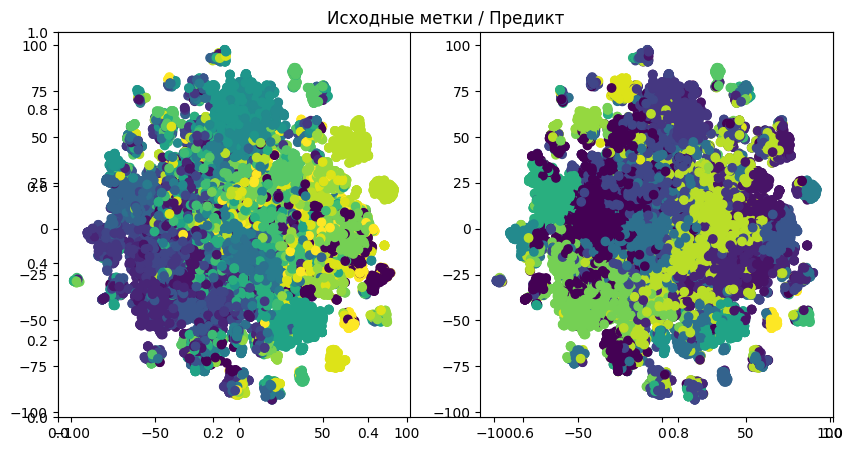

0.08578146802278623
0.25551974150135986


In [88]:
## Пробуем первый способ изменения размерности данных
svd = TruncatedSVD(n_components=50, random_state=42)
X_svd = svd.fit_transform(X_Tfidf)

tsne = TSNE(n_components=2, random_state=42)
X_2 = tsne.fit_transform(X_svd)

yp = get_yp(X_svd, names)
plot_data(X_2, yp, y)
get_metrics(y, yp)

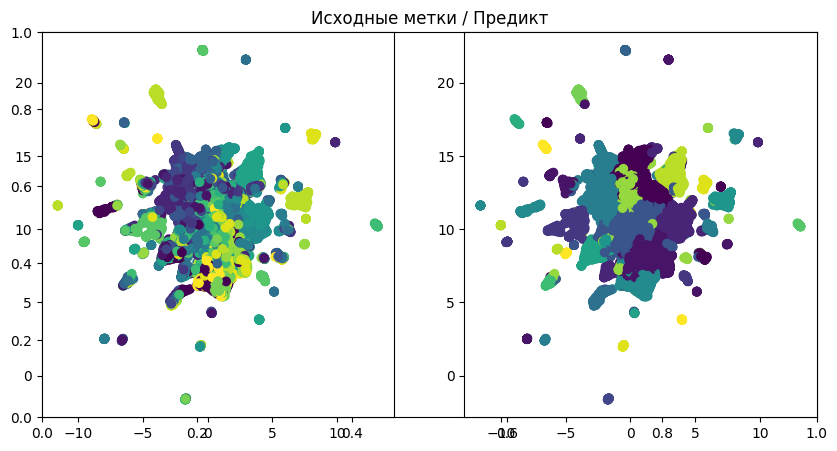

0.15648534643668915
0.31528626220699674


In [90]:
## Пробуем через umap

import umap
X_50 = umap.UMAP(n_components=50).fit_transform(X_svd)
X_2 = umap.UMAP(n_components=2).fit_transform(X_svd)

yp = get_yp(X_50, names)
plot_data(X_2, yp, y)
get_metrics(y, yp)